In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

df = pd.read_csv('/content/telecom_churn_raw.csv')
df.head(15)

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,Female,0,Yes,Yes,41,"Jan 31, 2023",Yes,Yes,Fiber optic,...,One year,Yes,Mailed check,91.26,"$3,869.1",83.3,0,2,Excellent,No
1,TC-11161,Female,1,No,Yes,19,2024-11-30,Yes,Yes,DSL,...,Month-to-month,Yes,Electronic check,67.81,"$1,230.23",16.8,4,2,Poor,Yes
2,TC-10375,Female,0,No,Yes,64,2021/03/03,Yes,Yes,No,...,Two Year,No,Bank transfer,39.46,2428.58,0.0,1,1,Poor,No
3,TC-10362,Female,0,Yes,No,NaN,2023-07-02,yes,Yes,FIBER OPTIC,...,2 year,yes,--,93.6,3497.22,Not Available,1,1,Excellent,No
4,TC-11216,Male,0,Yes,No,24,"Jul 01, 2024",Yes,Yes,DSL,...,Month-to-month,False,Bank transfer,73.94,1710.9,40.6,3,NaN,avg,No
5,TC-10501,Male,0,Yes,No,4,01/03/2026,Yes,No,DSL,...,Month-to-month,No,NaN,64.91,252.83,NaN,4,NaN,NaN,Yes
6,TC-10143,male,0,Yes,No,17,2025-01-30,Yes,No,Fiber optic,...,Month-to-month,No,Electronic check,107.66,1909.15,77.6,3,1,POOR,Yes
7,TC-10791,Male,0,No,No,25,2024-05-31,Yes,Yes,No,...,Month-to-month,No,Bank transfer,33.68,872.93,0.0,3,0,poor,No
8,TC-10035,Female,no,No,No,31,01/12/2023,Yes,Yes,Fiber optic,...,Monthly,No,Credit card,105.25,3299.93,139.3,4,1,poor,Yes
9,TC-10826,Male,0,No,No,13,2025-05-31,Yes,No,Fiber optic,...,Month-to-month,Yes,Bank transfer,82.04,1033.47,200.9,2,0,POOR,Yes


In [2]:
df.shape

(1300, 23)

In [3]:
df.dtypes

customer_id              str
gender                   str
senior_citizen           str
partner                  str
dependents               str
tenure_months            str
signup_date              str
phone_service            str
multiple_lines           str
internet_service         str
online_security          str
tech_support             str
streaming_tv             str
contract_type            str
paperless_billing        str
payment_method           str
monthly_charges          str
total_charges            str
avg_monthly_gb           str
support_calls            str
late_payments            str
customer_satisfaction    str
churn                    str
dtype: object

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1300 entries, 0 to 1299
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   customer_id            1300 non-null   str  
 1   gender                 1272 non-null   str  
 2   senior_citizen         1300 non-null   str  
 3   partner                1279 non-null   str  
 4   dependents             1300 non-null   str  
 5   tenure_months          1269 non-null   str  
 6   signup_date            1278 non-null   str  
 7   phone_service          1300 non-null   str  
 8   multiple_lines         1300 non-null   str  
 9   internet_service       1273 non-null   str  
 10  online_security        1269 non-null   str  
 11  tech_support           1273 non-null   str  
 12  streaming_tv           1300 non-null   str  
 13  contract_type          1279 non-null   str  
 14  paperless_billing      1300 non-null   str  
 15  payment_method         1260 non-null   str  
 16 

In [5]:
df.describe()

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
count,1300,1272,1300,1279,1300,1269,1278,1300,1300,1273,...,1279,1300,1260,1266,1273,1237,1255,1258,1228,1291
unique,1251,13,6,14,12,87,233,12,3,11,...,14,12,17,1087,1212,722,14,10,33,14
top,TC-10143,Female,0,Yes,No,12,2023-10-01,Yes,No,Fiber optic,...,Month-to-month,Yes,Electronic check,18.25,?,0.0,1,0,Average,No
freq,2,562,1006,604,825,45,29,1056,575,514,...,645,664,387,25,7,235,359,575,287,815


In [6]:
hidden = ["--", "Not Available", "?", ""]
print("Real NaN:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nHidden missing (--, Not Available, ?, blank):")
hid = df.astype(str).apply(lambda s: s.str.strip().isin(hidden)).sum()
print(hid[hid > 0])

Real NaN:
gender                   28
partner                  21
tenure_months            31
signup_date              22
internet_service         27
online_security          31
tech_support             27
contract_type            21
payment_method           40
monthly_charges          34
total_charges            27
avg_monthly_gb           63
support_calls            45
late_payments            42
customer_satisfaction    72
churn                     9
dtype: int64

Hidden missing (--, Not Available, ?, blank):
gender                   10
partner                   4
tenure_months             6
signup_date               4
internet_service         11
online_security           7
tech_support             12
contract_type             5
payment_method           12
monthly_charges          18
total_charges            17
avg_monthly_gb           12
support_calls            22
late_payments            14
customer_satisfaction    30
churn                     4
dtype: int64


In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

txt = [c for c in df.select_dtypes(include=["object", "string"]).columns]
tmp = df.copy()
for col in txt:
    tmp[col] = tmp[col].astype(str).str.strip().str.lower()
print("Duplicates after fixing spaces/case:", tmp.duplicated().sum())
print("Repeated customer_id:", df["customer_id"].duplicated().sum())

Exact duplicate rows: 35
Duplicates after fixing spaces/case: 50
Repeated customer_id: 49


In [8]:
cat_cols = ["gender", "senior_citizen", "partner", "dependents", "phone_service", "multiple_lines",
            "internet_service", "online_security", "tech_support", "streaming_tv", "contract_type",
            "paperless_billing", "payment_method", "customer_satisfaction", "churn"]
for col in cat_cols:
    print(col, "->", df[col].unique().tolist(), "\n")

gender -> ['Female', 'Male', 'male', 'Male ', nan, 'Not Available', 'fem', 'FEMALE', 'MALE', 'M', 'female', 'F', 'FEM', '--'] 

senior_citizen -> ['0', '1', 'no', 'Yes', 'No', 'yes'] 

partner -> ['Yes', 'No', 'N', 'yes', '0', nan, 'NO', 'no', 'Y', 'True', '1', '--', 'False', 'YES', 'Not Available'] 

dependents -> ['Yes', 'No', 'N', 'False', '0', 'True', 'no', 'NO', '1', 'Y', 'yes', 'YES'] 

phone_service -> ['Yes', 'yes', 'True', 'No', 'Y', '1', 'YES', 'NO', 'no', 'N', 'False', '0'] 

multiple_lines -> ['Yes', 'No', 'No phone service'] 

internet_service -> ['Fiber optic', 'DSL', 'No', 'FIBER OPTIC', 'Fiber', '--', 'Fibre', 'Dsl ', nan, 'fiber optic', 'dsl', 'Not Available'] 

online_security -> ['No', 'Yes', 'No internet service', nan, 'Not Available', '--'] 

tech_support -> [nan, 'No', 'No internet service', 'Yes', '--', 'Not Available'] 

streaming_tv -> ['No', 'No internet service', 'Yes'] 

contract_type -> ['One year', 'Month-to-month', 'Two Year', '2 year', 'Monthly', 'Two ye

In [9]:
num_cols = ["tenure_months", "monthly_charges", "total_charges", "avg_monthly_gb", "support_calls", "late_payments"]
for col in num_cols:
    bad = df[col][pd.to_numeric(df[col], errors="coerce").isna() & df[col].notna()]
    print(col, "-> non-numeric values:", bad.unique().tolist()[:8])

tenure_months -> non-numeric values: ['Not Available', '--']
monthly_charges -> non-numeric values: ['98.63 USD', '--', '67.66 USD', '50.11 USD', '63.2 USD', '68.69 USD', '103.2 USD', '91.74 USD']
total_charges -> non-numeric values: ['$3,869.1', '$1,230.23', '$1,151.82', '$601.86', '$529.24', 'Not Available', '$1,297.66', '$992.72']
avg_monthly_gb -> non-numeric values: ['Not Available', '--']
support_calls -> non-numeric values: ['--', 'Not Available']
late_payments -> non-numeric values: ['--', 'Not Available']


### Data audit report

| Column | Problem found |
|---|---|
| all columns | Hidden missing values written as `--`, `Not Available`, `?` and blank spaces (not NaN) |
| gender, partner, tenure_months, signup_date, internet_service, online_security, tech_support, contract_type, payment_method, monthly_charges, total_charges, avg_monthly_gb, support_calls, late_payments, customer_satisfaction, churn | Real NaN values |
| customer_id | Repeated ids and exact duplicate rows, plus near-duplicates that differ only in spaces or letter case |
| gender | `Male, male, MALE, M, Male ` and `Female, fem, FEM, F` for the same value |
| senior_citizen, partner, dependents, phone_service, paperless_billing, churn | Yes/No written as `Yes, yes, Y, True, 1` and `No, no, N, False, 0`; churn also has `Churned` and `Stayed` |
| internet_service | `Fiber, Fibre, FIBER OPTIC`, `Dsl ` (spaces and spelling) |
| contract_type | `M2M, Monthly, Month to Month, 1 year, 2 year` and similar |
| payment_method | `E-check, CC, Credit Card (auto), Bank Transfer (auto)` and similar |
| customer_satisfaction | Spelling mistakes (`Avrage, poorr, Pooor, excelent`), `avg`, `V.Good`, extra spaces |
| monthly_charges, total_charges | Stored as text: `$3,869.1`, `101.56 USD` |
| tenure_months, monthly_charges, avg_monthly_gb, support_calls | Impossible values (negative numbers) and extreme values (`999`, `9999`, `1250`, `99`) |
| signup_date | Mixed date formats and impossible dates like `31/02/2023`; stored as text |

In [10]:
df = df.replace(["--", "Not Available", "?", " "], np.nan)
for col in df.select_dtypes(include=["object", "string"]).columns.drop(["customer_id", "signup_date"]):
    df[col] = df[col].str.strip().str.lower()

In [11]:
yes_no = {"yes": "yes", "y": "yes", "true": "yes", "1": "yes", "churned": "yes",
          "no": "no", "n": "no", "false": "no", "0": "no", "stayed": "no"}
for col in ["senior_citizen", "partner", "dependents", "phone_service", "paperless_billing", "churn"]:
    df[col] = df[col].map(yes_no)

df["gender"] = df["gender"].replace({"m": "male", "f": "female", "fem": "female"})
df["internet_service"] = df["internet_service"].replace({"fiber": "fiber optic", "fibre": "fiber optic"})
df["contract_type"] = df["contract_type"].replace({"m2m": "month-to-month", "monthly": "month-to-month",
    "month to month": "month-to-month", "1 year": "one year", "2 year": "two year"})
df["payment_method"] = df["payment_method"].replace({"e-check": "electronic check", "cc": "credit card",
    "credit card (auto)": "credit card", "bank transfer (auto)": "bank transfer"})
df["customer_satisfaction"] = df["customer_satisfaction"].replace({"avg": "average", "avrage": "average",
    "poorr": "poor", "pooor": "poor", "poooor": "poor", "excelent": "excellent", "v.good": "very good"})

for col in ["gender", "internet_service", "contract_type", "payment_method", "customer_satisfaction"]:
    print(col, "->", df[col].unique().tolist())

gender -> ['female', 'male', nan]
internet_service -> ['fiber optic', 'dsl', 'no', nan]
contract_type -> ['one year', 'month-to-month', 'two year', nan]
payment_method -> ['mailed check', 'electronic check', 'bank transfer', nan, 'credit card']
customer_satisfaction -> ['excellent', 'poor', 'average', nan, 'good', 'very good']


In [12]:
for col in ["tenure_months", "monthly_charges", "total_charges", "avg_monthly_gb", "support_calls", "late_payments"]:
    df[col] = df[col].astype(str).str.replace(r"[$,]|usd", "", regex=True).str.strip()
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["signup_date"] = pd.to_datetime(df["signup_date"], format="mixed", dayfirst=True, errors="coerce")
df["churn"] = df["churn"].map({"yes": 1, "no": 0})
df["senior_citizen"] = df["senior_citizen"].map({"yes": 1, "no": 0})
df.dtypes

customer_id                         str
gender                              str
senior_citizen                    int64
partner                             str
dependents                          str
tenure_months                   float64
signup_date              datetime64[us]
phone_service                       str
multiple_lines                      str
internet_service                    str
online_security                     str
tech_support                        str
streaming_tv                        str
contract_type                       str
paperless_billing                   str
payment_method                      str
monthly_charges                 float64
total_charges                   float64
avg_monthly_gb                  float64
support_calls                   float64
late_payments                   float64
customer_satisfaction               str
churn                           float64
dtype: object

In [13]:
print("Before:", df.shape)
df = df.drop_duplicates()
df = df.drop_duplicates(subset="customer_id")
print("After:", df.shape)

Before: (1300, 23)
After: (1251, 23)


In [14]:
num_cols = ["tenure_months", "monthly_charges", "total_charges", "avg_monthly_gb", "support_calls", "late_payments"]
for col in num_cols:
    df.loc[df[col] < 0, col] = np.nan
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    df.loc[df[col] > q3 + 3 * (q3 - q1), col] = np.nan
df.loc[df["monthly_charges"] == 0, "monthly_charges"] = np.nan
df[num_cols].describe()

,tenure_months,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments
count,1195.000000,1190.000000,1209.000000,1165.000000,1175.000000,1194.000000
mean,26.165690,72.861277,1909.993987,63.888240,1.708936,0.798995
std,15.781358,26.034372,1411.081733,62.206662,1.440606,0.925452
min,0.000000,18.250000,18.150000,0.000000,0.000000,0.000000
25%,14.000000,54.375000,827.850000,14.000000,1.000000,0.000000
50%,24.000000,74.785000,1582.060000,46.900000,1.000000,1.000000
75%,36.000000,95.335000,2622.570000,98.600000,3.000000,1.000000
max,71.000000,120.430000,7121.660000,339.800000,7.000000,4.000000


In [15]:
df = df.dropna(subset=["churn"])
df["churn"] = df["churn"].astype(int)

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=["object", "string"]).columns.drop("customer_id"):
    df[col] = df[col].fillna(df[col].mode()[0])

df.isnull().sum()

customer_id               0
gender                    0
senior_citizen            0
partner                   0
dependents                0
tenure_months             0
signup_date              62
phone_service             0
multiple_lines            0
internet_service          0
online_security           0
tech_support              0
streaming_tv              0
contract_type             0
paperless_billing         0
payment_method            0
monthly_charges           0
total_charges             0
avg_monthly_gb            0
support_calls             0
late_payments             0
customer_satisfaction     0
churn                     0
dtype: int64

### Cleaning decisions

- **Hidden missing values** (`--`, `Not Available`, `?`, blank) were turned into NaN so they are treated like real missing values.
- **Text** was stripped and lower-cased, then spelling variants were mapped to one value (for example `M2M`, `Monthly` -> `month-to-month`).
- **Yes/No columns** were mapped to one format; `churn` and `senior_citizen` became 1/0 numbers.
- **Numeric columns** stored as text (`$3,869.1`, `101.56 USD`) were converted to numbers.
- **Duplicates** were removed after standardizing, so near-duplicates were caught too. Repeated `customer_id` rows were removed (first one kept).
- **Impossible values** (negative tenure, charges, calls, GB; monthly charge of 0) were set to NaN. **Extreme values** (above Q3 + 3 x IQR, like 999 months or 9999 GB) were also set to NaN, then filled with the median.
- **Missing numeric values** were filled with the median (not affected by outliers). **Missing categories** were filled with the mode.
- **Missing churn** rows were dropped, because the target must not be guessed.
- `signup_date` has impossible dates (like 31/02/2023); they became NaT and were left empty because the column is not used for modelling.

In [16]:
df.to_csv("telecom_churn_clean.csv", index=False)
df.head()

,customer_id,gender,senior_citizen,partner,dependents,tenure_months,signup_date,phone_service,multiple_lines,internet_service,...,contract_type,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,support_calls,late_payments,customer_satisfaction,churn
0,TC-10348,female,0,yes,yes,41.0,2023-01-31,yes,yes,fiber optic,...,one year,yes,mailed check,91.26,3869.10,83.3,0.0,2.0,excellent,0
1,TC-11161,female,1,no,yes,19.0,2024-11-30,yes,yes,dsl,...,month-to-month,yes,electronic check,67.81,1230.23,16.8,4.0,2.0,poor,1
2,TC-10375,female,0,no,yes,64.0,2021-03-03,yes,yes,no,...,two year,no,bank transfer,39.46,2428.58,0.0,1.0,1.0,poor,0
3,TC-10362,female,0,yes,no,24.0,2023-02-07,yes,yes,fiber optic,...,two year,yes,electronic check,93.60,3497.22,47.0,1.0,1.0,excellent,0
4,TC-11216,male,0,yes,no,24.0,2024-07-01,yes,yes,dsl,...,month-to-month,no,bank transfer,73.94,1710.90,40.6,3.0,1.0,average,0


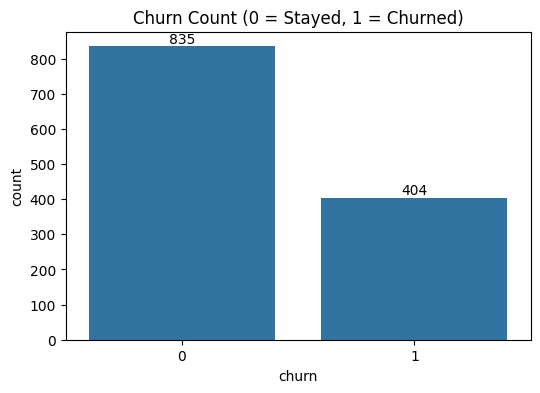

Insight: 33% of customers churned, so the data is imbalanced.


In [17]:
plt.figure(figsize=(6, 4))
a = sns.countplot(data=df, x="churn")
a.bar_label(a.containers[0])
plt.title("Churn Count (0 = Stayed, 1 = Churned)")
plt.show()
print(f"Insight: {df['churn'].mean():.0%} of customers churned, so the data is imbalanced.")

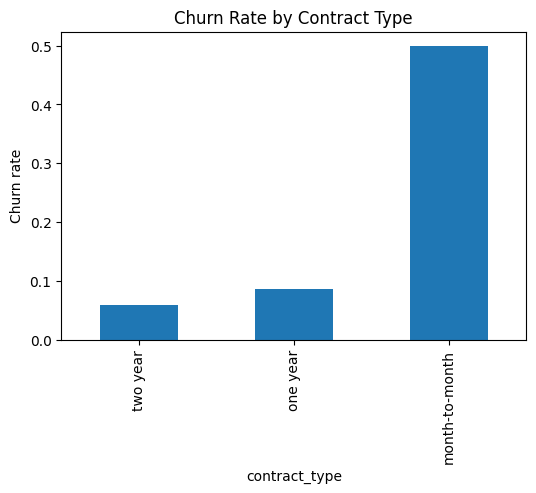

Insight: month-to-month customers churn the most (50%), two year the least (6%).


In [18]:
rate = df.groupby("contract_type")["churn"].mean().sort_values()
rate.plot(kind="bar", figsize=(6, 4), title="Churn Rate by Contract Type")
plt.ylabel("Churn rate")
plt.show()
print(f"Insight: {rate.index[-1]} customers churn the most ({rate.iloc[-1]:.0%}), {rate.index[0]} the least ({rate.iloc[0]:.0%}).")

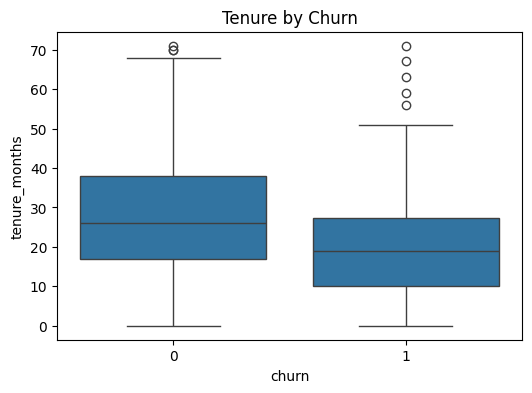

Insight: churned customers have a median tenure of 19 months vs 26 months for the others.


In [19]:
plt.figure(figsize=(6, 4))
sns.boxplot(data=df, x="churn", y="tenure_months")
plt.title("Tenure by Churn")
plt.show()
m = df.groupby("churn")["tenure_months"].median()
print(f"Insight: churned customers have a median tenure of {m[1]:.0f} months vs {m[0]:.0f} months for the others.")

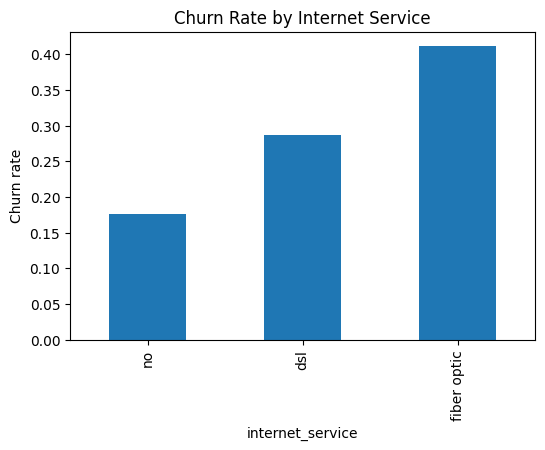

Insight: fiber optic users churn the most (41%) and no users the least (18%).


In [20]:
rate = df.groupby("internet_service")["churn"].mean().sort_values()
rate.plot(kind="bar", figsize=(6, 4), title="Churn Rate by Internet Service")
plt.ylabel("Churn rate")
plt.show()
print(f"Insight: {rate.index[-1]} users churn the most ({rate.iloc[-1]:.0%}) and {rate.index[0]} users the least ({rate.iloc[0]:.0%}).")

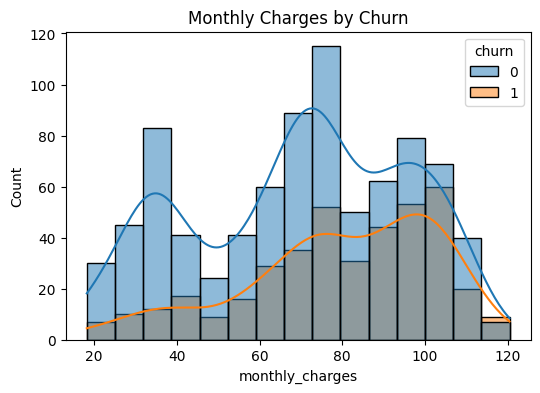

Insight: churned customers pay 80 on average per month vs 70 for the others.


In [21]:
plt.figure(figsize=(6, 4))
sns.histplot(data=df, x="monthly_charges", hue="churn", kde=True)
plt.title("Monthly Charges by Churn")
plt.show()
m = df.groupby("churn")["monthly_charges"].mean()
print(f"Insight: churned customers pay {m[1]:.0f} on average per month vs {m[0]:.0f} for the others.")

In [22]:
def add_features(d):
    d = d.copy()
    d["avg_spend_per_month"] = d["total_charges"] / (d["tenure_months"] + 1)
    d["new_customer"] = (d["tenure_months"] <= 12).astype(int)
    return d

df = add_features(df)
df[["tenure_months", "total_charges", "avg_spend_per_month", "new_customer"]].head()

,tenure_months,total_charges,avg_spend_per_month,new_customer
0,41.0,3869.10,92.121429,0
1,19.0,1230.23,61.511500,0
2,64.0,2428.58,37.362769,0
3,24.0,3497.22,139.888800,0
4,24.0,1710.90,68.436000,0


In [23]:
features = ["gender", "partner", "tenure_months", "monthly_charges", "total_charges",
            "internet_service", "payment_method", "contract_type", "avg_spend_per_month", "new_customer"]
X = df[features]
y = df["churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

def pipe(model):
    return make_pipeline(clone(preprocessor), model)

def get_scores(name, model):
    pred = model.predict(X_test)
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(y_test, pred, zero_division=0),
            "Recall": recall_score(y_test, pred, zero_division=0),
            "F1-score": f1_score(y_test, pred, zero_division=0)}

In [24]:
models = {
    "Logistic Regression": pipe(LogisticRegression(max_iter=1000)),
    "Decision Tree": pipe(DecisionTreeClassifier(random_state=42)),
    "Random Forest": pipe(RandomForestClassifier(random_state=42)),
    "XGBoost": pipe(XGBClassifier(eval_metric="logloss", random_state=42))
}

for model in models.values():
    model.fit(X_train, y_train)

baseline = pd.DataFrame([get_scores(n, m) for n, m in models.items()])
baseline.round(3)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.730,0.609,0.481,0.538
1,Decision Tree,0.673,0.500,0.469,0.484
2,Random Forest,0.718,0.587,0.457,0.514
3,XGBoost,0.718,0.596,0.420,0.493


In [25]:
rf_params = {
    "randomforestclassifier__n_estimators": [100, 150, 200],
    "randomforestclassifier__max_depth": [None, 10, 20],
    "randomforestclassifier__min_samples_split": [2, 5],
    "randomforestclassifier__min_samples_leaf": [1, 2]
}
xgb_params = {
    "xgbclassifier__n_estimators": [100, 150, 200],
    "xgbclassifier__max_depth": [3, 4, 5],
    "xgbclassifier__learning_rate": [0.03, 0.1, 0.2],
    "xgbclassifier__subsample": [0.8, 1.0]
}

rf_search = RandomizedSearchCV(pipe(RandomForestClassifier(random_state=42)), rf_params,
                               n_iter=5, scoring="f1", cv=3, random_state=42, n_jobs=-1)
xgb_search = RandomizedSearchCV(pipe(XGBClassifier(eval_metric="logloss", random_state=42)), xgb_params,
                                n_iter=5, scoring="f1", cv=3, random_state=42, n_jobs=-1)

rf_search.fit(X_train, y_train)
xgb_search.fit(X_train, y_train)

rf_tuned = rf_search.best_estimator_
xgb_tuned = xgb_search.best_estimator_
print("Best RF:", rf_search.best_params_)
print("Best XGB:", xgb_search.best_params_)

Best RF: {'randomforestclassifier__n_estimators': 100, 'randomforestclassifier__min_samples_split': 2, 'randomforestclassifier__min_samples_leaf': 2, 'randomforestclassifier__max_depth': 20}
Best XGB: {'xgbclassifier__subsample': 1.0, 'xgbclassifier__n_estimators': 100, 'xgbclassifier__max_depth': 3, 'xgbclassifier__learning_rate': 0.1}


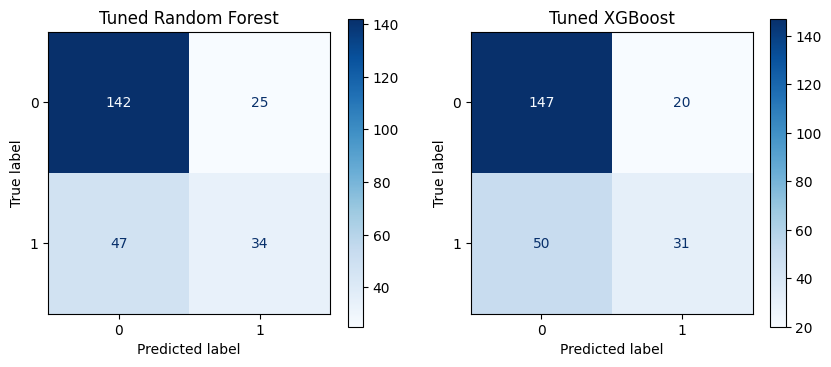

In [26]:
tuned = {"Tuned Random Forest": rf_tuned, "Tuned XGBoost": xgb_tuned}

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (name, model) in zip(ax, tuned.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=a, cmap="Blues")
    a.set_title(name)
plt.show()

In [27]:
final_table = pd.DataFrame([get_scores(n, m) for n, m in {**models, **tuned}.items()])
final_table = final_table.sort_values("F1-score", ascending=False).round(3)
final_table

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.730,0.609,0.481,0.538
2,Random Forest,0.718,0.587,0.457,0.514
3,XGBoost,0.718,0.596,0.420,0.493
4,Tuned Random Forest,0.710,0.576,0.420,0.486
1,Decision Tree,0.673,0.500,0.469,0.484
5,Tuned XGBoost,0.718,0.608,0.383,0.470


### Final model choice

I selected **[model name]** as my final model because its F1-score was **[value]**, the highest in the table, with recall **[value]** and precision **[value]**. For churn, recall matters because a missed churner is a lost customer, and F1 balances it with precision. It also beat its untuned version, which shows tuning helped. [Add one line about why you rejected the others, e.g. Logistic Regression is simple but scored lower.]

In [28]:
final_model = max(tuned.values(), key=lambda m: f1_score(y_test, m.predict(X_test)))
joblib.dump(final_model, "churn_model.pkl")
print("Saved:", final_model.steps[-1][0])

Saved: randomforestclassifier


In [29]:
print(df["payment_method"].unique(), df["internet_service"].unique(), df["contract_type"].unique())

<StringArray>
['mailed check', 'electronic check', 'bank transfer', 'credit card']
Length: 4, dtype: str <StringArray>
['fiber optic', 'dsl', 'no']
Length: 3, dtype: str <StringArray>
['one year', 'month-to-month', 'two year']
Length: 3, dtype: str


In [30]:
#@title Telecom Customer Churn Prediction Form

gender = "female" #@param ["female", "male"]
partner = "no" #@param ["yes", "no"]
tenure_months = 19 #@param {type:"number"}
monthly_charges = 67.81 #@param {type:"number"}
total_charges = 1230.23 #@param {type:"number"}
internet_service = "dsl" #@param ["dsl", "fiber optic", "no"]
payment_method = "electronic check" #@param ["electronic check", "mailed check", "bank transfer", "credit card"]
contract_type = "two year" #@param ["month-to-month", "one year", "two year"]

model = joblib.load("churn_model.pkl")

new = pd.DataFrame([{"gender": gender, "partner": partner, "tenure_months": tenure_months,
                     "monthly_charges": monthly_charges, "total_charges": total_charges,
                     "internet_service": internet_service, "payment_method": payment_method,
                     "contract_type": contract_type}])
new = add_features(new)[features]

pred = model.predict(new)[0]
prob = model.predict_proba(new)[0][1]
print("Churn Prediction:", "Yes" if pred == 1 else "No")
print(f"Churn Probability: {prob:.2%}")

Churn Prediction: No
Churn Probability: 3.98%
